# WildfireSpreadTS (WSTS) — Exploratory Data Analysis

## Project
FireGuard: Next-Day Wildfire Spread Prediction

## Role
Role 1 — WSTS / Geospatial Data Engineer

## Objective
This notebook performs a reproducible exploratory inspection of the WildfireSpreadTS dataset.

The analysis covers:

1. Dataset inventory and organization.
2. GeoTIFF metadata and spatial properties.
3. Original 23-band feature inspection.
4. Processed 40-channel loader inspection.
5. Active-fire target distribution.
6. Data quality and missing-value analysis.

## Dataset provenance
- Dataset: WildfireSpreadTS
- Zenodo: https://zenodo.org/records/8006177
- Baseline repository: https://github.com/SebastianGer/WildfireSpreadTS
- Pinned baseline commit: `f62dc49f2c2a6d249c071533ae5340c0d01bfb95`

## Data location
The extracted dataset is stored in Google Drive. Raw dataset files are not committed to GitHub.

## Important note
This notebook is intended for Phase 1 dataset inspection. It does not implement model training, data splitting, or Phase 2 preprocessing.

In [1]:
from pathlib import Path

notebook_dir = Path("/content/fireguard/notebooks")
notebook_dir.mkdir(parents=True, exist_ok=True)

print("Notebook directory:", notebook_dir)
print("Directory exists:", notebook_dir.exists())

Notebook directory: /content/fireguard/notebooks
Directory exists: True


In [3]:
# ==========================================
# 1. ENVIRONMENT AND DATASET CONFIGURATION
# ==========================================

from pathlib import Path
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from google.colab import drive

warnings.filterwarnings("ignore")

# Mount Google Drive
drive.mount("/content/drive")

# Project paths
PROJECT_ROOT = Path("/content/fireguard")

DATA_ROOT = Path(
    "/content/drive/MyDrive/FireGuard/data/extracted"
)

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/FireGuard/data/manifests/wsts_event_metadata.csv"
)

# Check paths
print("Project root exists:", PROJECT_ROOT.exists())
print("Dataset root exists:", DATA_ROOT.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

assert DATA_ROOT.exists(), "Dataset directory not found."
assert MANIFEST_PATH.exists(), "Event metadata manifest not found."

# Load event metadata
event_metadata = pd.read_csv(MANIFEST_PATH)

print("\nEvent metadata shape:", event_metadata.shape)
print("\nEvents by year:")
display(event_metadata["year"].value_counts().sort_index())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root exists: True
Dataset root exists: True
Manifest exists: True

Event metadata shape: (607, 24)

Events by year:


,count
year,
2018,176
2019,74
2020,201
2021,156


In [4]:
# ==========================================
# 2. DATASET INVENTORY
# ==========================================

year_summary = []

for year in sorted(event_metadata["year"].unique()):

    year_path = DATA_ROOT / str(year)

    # Find event directories
    event_dirs = sorted([
        p for p in year_path.iterdir()
        if p.is_dir()
    ])

    # Count TIFF files
    tiff_count = sum(
        len(list(event_dir.glob("*.tif")))
        for event_dir in event_dirs
    )

    year_summary.append({
        "year": int(year),
        "event_count": len(event_dirs),
        "tiff_count": tiff_count
    })

year_summary_df = pd.DataFrame(year_summary)

print("WSTS DATASET INVENTORY")
display(year_summary_df)

print("\nTotal events:", year_summary_df["event_count"].sum())
print("Total TIFF files:", year_summary_df["tiff_count"].sum())

# Compare directory counts with manifest
manifest_counts = (
    event_metadata.groupby("year")
    .size()
    .rename("manifest_event_count")
)

comparison = (
    year_summary_df.set_index("year")
    .join(manifest_counts)
)

comparison["counts_match"] = (
    comparison["event_count"] ==
    comparison["manifest_event_count"]
)

print("\nManifest vs actual directory comparison:")
display(comparison)

WSTS DATASET INVENTORY


,year,event_count,tiff_count
0,2018,176,3773
1,2019,74,1425
2,2020,201,4292
3,2021,156,4117



Total events: 607
Total TIFF files: 13607

Manifest vs actual directory comparison:


,event_count,tiff_count,manifest_event_count,counts_match
year,,,,
2018,176,3773,176,True
2019,74,1425,74,True
2020,201,4292,201,True
2021,156,4117,156,True


In [5]:
# ==========================================
# 3. FILE COUNT RECONCILIATION
# ==========================================

from collections import Counter

extension_counts = Counter()
total_files = 0

for path in DATA_ROOT.rglob("*"):
    if path.is_file():
        total_files += 1
        extension = path.suffix.lower() or "[no extension]"
        extension_counts[extension] += 1

print("Total files under extracted dataset:", total_files)
print("\nFiles by extension:")

for extension, count in sorted(extension_counts.items()):
    print(f"{extension}: {count}")

print("\nTIFF files from directory scan:",
      extension_counts[".tif"])

print("\nPreviously recorded extracted files: 14,218")
print("Current total files:", total_files)
print("Difference:", 14218 - total_files)

Total files under extracted dataset: 13607

Files by extension:
.tif: 13607

TIFF files from directory scan: 13607

Previously recorded extracted files: 14,218
Current total files: 13607
Difference: 611


In [6]:
# ==========================================
# 4. EVENT-LEVEL TIFF COUNT VALIDATION
# ==========================================

manifest = pd.read_csv(MANIFEST_PATH)

actual_counts = []

for _, row in manifest.iterrows():

    year = int(row["year"])
    event_id = row["event_id"]

    event_path = DATA_ROOT / str(year) / event_id

    actual_tiffs = (
        len(list(event_path.glob("*.tif")))
        if event_path.exists()
        else 0
    )

    actual_counts.append({
        "year": year,
        "event_id": event_id,
        "manifest_tiff_count": row["tiff_count"],
        "actual_tiff_count": actual_tiffs,
        "directory_exists": event_path.exists()
    })

event_check = pd.DataFrame(actual_counts)

print("Events checked:", len(event_check))
print("Missing directories:",
      (~event_check["directory_exists"]).sum())

print("Events with count mismatch:",
      (event_check["manifest_tiff_count"] !=
       event_check["actual_tiff_count"]).sum())

display(
    event_check[
        event_check["manifest_tiff_count"] !=
        event_check["actual_tiff_count"]
    ].head(20)
)

Events checked: 607
Missing directories: 0
Events with count mismatch: 0


,year,event_id,manifest_tiff_count,actual_tiff_count,directory_exists


In [7]:
# ==========================================
# 5. GEOTIFF METADATA INSPECTION
# ==========================================

SAMPLE_EVENT = "fire_21458798"
SAMPLE_YEAR = 2018

sample_event_dir = DATA_ROOT / str(SAMPLE_YEAR) / SAMPLE_EVENT

tiff_files = sorted(sample_event_dir.glob("*.tif"))

print("Event:", SAMPLE_EVENT)
print("Number of TIFF files:", len(tiff_files))
print("First TIFF:", tiff_files[0].name)
print("Last TIFF:", tiff_files[-1].name)

# Inspect January 6, 2018
sample_tiff = sample_event_dir / "2018-01-06.tif"

with rasterio.open(sample_tiff) as src:

    print("\n--- Raster metadata ---")
    print("Width:", src.width)
    print("Height:", src.height)
    print("Band count:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data types:", src.dtypes)
    print("Nodata:", src.nodata)
    print("Bounds:", src.bounds)
    print("Transform:", src.transform)

    raster = src.read()

print("\nArray shape:", raster.shape)
print("Array dtype:", raster.dtype)

Event: fire_21458798
Number of TIFF files: 14
First TIFF: 2018-01-01.tif
Last TIFF: 2018-01-14.tif

--- Raster metadata ---
Width: 247
Height: 304
Band count: 23
CRS: EPSG:32610
Resolution: (375.0, 375.0)
Data types: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
Nodata: None
Bounds: BoundingBox(left=697500.0, bottom=4022625.0, right=790125.0, top=4136625.0)
Transform: | 375.00, 0.00, 697500.00|
| 0.00,-375.00, 4136625.00|
| 0.00, 0.00, 1.00|

Array shape: (23, 304, 247)
Array dtype: float32


### **Sample GeoTIFF Metadata Inspection**
## Sample GeoTIFF Metadata Inspection

Sample event: `fire_21458798` (2018)

- Number of daily TIFF files: 14
- Date range: 2018-01-01 to 2018-01-14
- Raster width: 247 columns
- Raster height: 304 rows
- Number of bands: 23
- Array layout: (bands, rows, columns)
- CRS: EPSG:32610
- Pixel resolution: 375 m × 375 m
- Data type: float32
- Dataset-level nodata metadata: None

The inspected raster has 23 float32 bands and a projected
375 m spatial grid. The absence of a dataset-level nodata
value does not imply that all individual band pixels are valid.

In [8]:
# 6. PER-BAND DATA QUALITY INSPECTION

import numpy as np
import pandas as pd
import rasterio

sample_tiff = (
    DATA_ROOT / "2018" / "fire_21458798" / "2018-01-06.tif"
)

with rasterio.open(sample_tiff) as src:
    raster = src.read()

band_quality = []

for band_idx in range(raster.shape[0]):
    band = raster[band_idx]

    finite_values = band[np.isfinite(band)]

    band_quality.append({
        "band_index": band_idx,
        "total_pixels": band.size,
        "nan_count": int(np.isnan(band).sum()),
        "positive_inf_count": int(np.isposinf(band).sum()),
        "negative_inf_count": int(np.isneginf(band).sum()),
        "finite_count": int(np.isfinite(band).sum()),
        "finite_min": (
            float(finite_values.min())
            if finite_values.size else np.nan
        ),
        "finite_max": (
            float(finite_values.max())
            if finite_values.size else np.nan
        ),
        "finite_mean": (
            float(finite_values.mean())
            if finite_values.size else np.nan
        )
    })

band_quality_df = pd.DataFrame(band_quality)

display(band_quality_df)

,band_index,total_pixels,nan_count,positive_inf_count,negative_inf_count,finite_count,finite_min,finite_max,finite_mean
0,0,75088,0,0,0,75088,857.000000,6694.000000,3984.554443
1,1,75088,0,0,0,75088,672.000000,13084.000000,6198.055176
2,2,75088,0,0,0,75088,-100.000000,12240.000000,6014.635254
3,3,75088,0,0,0,75088,-5354.000000,9246.000000,3342.108398
4,4,75088,0,0,0,75088,-1212.000000,9577.000000,1791.945435
5,5,75088,0,0,0,75088,0.000000,11.000000,1.377967
6,6,75088,0,0,0,75088,1.200000,2.400000,2.050342
7,7,75088,0,0,0,75088,156.000000,342.000000,300.261932
8,8,75088,0,0,0,75088,278.500000,287.100006,282.168182
9,9,75088,0,0,0,75088,284.000000,290.799988,288.642761


## Per-band Data Quality Inspection

Inspected file: `2018/ fire_21458798 / 2018-01-06.tif`

The raster contains 23 bands and 75,088 pixels per band.

- Bands 0–21: all 75,088 pixels are finite.
- Band 22 (Active fire): all 75,088 pixels are NaN.
- Positive and negative infinity values: none in any band.

The active-fire input band is entirely missing in this particular
daily raster. The baseline loader replaces NaNs in the active-fire
input channel with zero.

This finding is specific to the inspected date and must not be
generalized to all events or dates. Physical units and scale factors
for the other channels require verification against their source
products and preprocessing code.

In [9]:
# 7. ACTIVE-FIRE BAND MISSINGNESS ACROSS THE EVENT

import numpy as np
import pandas as pd
import rasterio

event_dir = DATA_ROOT / "2018" / "fire_21458798"
tiff_files = sorted(event_dir.glob("*.tif"))

active_fire_quality = []

for tiff_path in tiff_files:
    with rasterio.open(tiff_path) as src:
        active_fire = src.read(23)

    total = active_fire.size
    finite_count = int(np.isfinite(active_fire).sum())
    nan_count = int(np.isnan(active_fire).sum())

    finite_values = active_fire[np.isfinite(active_fire)]

    active_fire_quality.append({
        "date": tiff_path.stem,
        "total_pixels": total,
        "finite_count": finite_count,
        "nan_count": nan_count,
        "finite_min": (
            float(finite_values.min())
            if finite_values.size else np.nan
        ),
        "finite_max": (
            float(finite_values.max())
            if finite_values.size else np.nan
        ),
        "positive_pixel_count": int(
            np.sum(finite_values > 0)
        )
    })

active_fire_quality_df = pd.DataFrame(active_fire_quality)

display(active_fire_quality_df)

,date,total_pixels,finite_count,nan_count,finite_min,finite_max,positive_pixel_count
0,2018-01-01,75088,4,75084,854.0,854.0,4
1,2018-01-02,75088,0,75088,NaN,NaN,0
2,2018-01-03,75088,0,75088,NaN,NaN,0
3,2018-01-04,75088,0,75088,NaN,NaN,0
4,2018-01-05,75088,0,75088,NaN,NaN,0
5,2018-01-06,75088,0,75088,NaN,NaN,0
6,2018-01-07,75088,10,75078,2006.0,2006.0,10
7,2018-01-08,75088,0,75088,NaN,NaN,0
8,2018-01-09,75088,0,75088,NaN,NaN,0
9,2018-01-10,75088,4,75084,2048.0,2048.0,4


## Active-fire Band Missingness Across the Event

Event: `fire_21458798` (2018-01-01 to 2018-01-14)

Band 22 (Active fire) was inspected across all 14 daily GeoTIFFs.

- Dates with finite active-fire pixels: 4
- Dates with an entirely NaN active-fire band: 10
- Total positive pixels across the 14 dates: 78

Finite active-fire values occurred on:
- 2018-01-01: 4 pixels, value 854
- 2018-01-07: 10 pixels, value 2006
- 2018-01-10: 4 pixels, value 2048
- 2018-01-11: 34 pixels, range 912–2030
- 2018-01-12: 26 pixels, range 848–2012

Correction: the dates with finite values are January 1, 7, 10, 11, and 12.
There are therefore 5 dates with finite values and 9 dates with
an entirely NaN active-fire band.

The baseline loader replaces NaNs in the active-fire input channel
with zero. This should not be interpreted as proof that the original
observation confirmed an absence of fire.

In [10]:
# 8. RAW ACTIVE-FIRE VS LOADER TARGET ALIGNMENT

import numpy as np
import rasterio
import torch

raw_target_path = (
    DATA_ROOT / "2018" / "fire_21458798" / "2018-01-07.tif"
)

with rasterio.open(raw_target_path) as src:
    raw_target_band = src.read(23)

raw_finite_positive = (
    np.isfinite(raw_target_band) & (raw_target_band > 0)
)

loader_target = y.numpy() if isinstance(y, torch.Tensor) else np.asarray(y)

print("Raw target date: 2018-01-07")
print("Raw finite positive pixels:", int(raw_finite_positive.sum()))
print("Loader target shape:", loader_target.shape)
print("Loader target positive pixels:", int((loader_target > 0).sum()))
print("Loader target unique values:", np.unique(loader_target))

NameError: name 'y' is not defined

In [11]:
print("dataset exists:", "dataset" in globals())
print("y exists:", "y" in globals())
print("torch imported:", "torch" in globals())

dataset exists: False
y exists: False
torch imported: True


In [13]:
# Recreate the official WSTS dataset

import sys
from pathlib import Path

PROJECT_ROOT = Path("/content/fireguard")
DATA_ROOT = Path("/content/drive/MyDrive/FireGuard/data/extracted")

sys.path.insert(0, str(PROJECT_ROOT))

from src.dataloader.FireSpreadDataset import FireSpreadDataset

dataset = FireSpreadDataset(
    data_dir=str(DATA_ROOT),
    included_fire_years=[2018],
    n_leading_observations=1,
    crop_side_length=256,
    load_from_hdf5=False,
    is_train=False,
    remove_duplicate_features=False,
    stats_years=[2018, 2019],
    return_doy=False
)

print("Dataset initialized.")
print("Number of samples:", len(dataset))

ModuleNotFoundError: No module named 'src'

In [14]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path("/content/fireguard")

print("Current working directory:", os.getcwd())
print("Project root exists:", PROJECT_ROOT.exists())
print("Project root:", PROJECT_ROOT)

if PROJECT_ROOT.exists():
    print("\nProject root contents:")
    for item in list(PROJECT_ROOT.iterdir())[:30]:
        print(item.name)

print("\nLoader file exists:",
      (PROJECT_ROOT / "src/dataloader/FireSpreadDataset.py").exists())

print("Python path contains project root:",
      str(PROJECT_ROOT) in sys.path)

Current working directory: /content
Project root exists: True
Project root: /content/fireguard

Project root contents:
notebooks

Loader file exists: False
Python path contains project root: True


In [15]:
from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

for root in search_roots:
    print(f"\nSearching under: {root}")

    if not root.exists():
        continue

    matches = list(root.glob("**/FireSpreadDataset.py"))

    for match in matches[:10]:
        print("Found:", match)


Searching under: /content

Searching under: /content/drive/MyDrive


In [16]:
import subprocess
from pathlib import Path

WSTS_ROOT = Path("/content/WildfireSpreadTS")
BASELINE_COMMIT = "f62dc49f2c2a6d249c071533ae5340c0d01bfb95"

if not WSTS_ROOT.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/SebastianGer/WildfireSpreadTS.git",
            str(WSTS_ROOT)
        ],
        check=True
    )

subprocess.run(
    ["git", "checkout", BASELINE_COMMIT],
    cwd=WSTS_ROOT,
    check=True
)

loader_path = WSTS_ROOT / "src/dataloader/FireSpreadDataset.py"

print("Baseline directory exists:", WSTS_ROOT.exists())
print("Loader exists:", loader_path.exists())
print("Pinned commit:", subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=WSTS_ROOT,
    text=True
).strip())

Baseline directory exists: True
Loader exists: True
Pinned commit: f62dc49f2c2a6d249c071533ae5340c0d01bfb95


In [18]:
dataloader_path = "/content/WildfireSpreadTS/src/dataloader/FireSpreadDataset.py"

with open(dataloader_path, "r") as f:
    content = f.read()

# Replace the failing torch import line with a robust local TypeVar definition
old_import = "from torch.utils.data.dataset import T_co"
new_import = "from typing import TypeVar\nT_co = TypeVar('T_co', covariant=True)"

if old_import in content:
    content = content.replace(old_import, new_import)
elif "T_co" not in content:
    # If the import wasn't there, inject it right after the torch imports
    content = content.replace("import torch", "import torch\nfrom typing import TypeVar\nT_co = TypeVar('T_co', covariant=True)")

with open(dataloader_path, "w") as f:
    f.write(content)

print("Successfully updated FireSpreadDataset.py with local TypeVar!")

Successfully updated FireSpreadDataset.py with local TypeVar!


In [19]:
from pathlib import Path

dataloader_path = Path(
    "/content/WildfireSpreadTS/src/dataloader/FireSpreadDataset.py"
)

content = dataloader_path.read_text()

print("Old T_co import remains:",
      "from torch.utils.data.dataset import T_co" in content)

print("TypeVar import exists:",
      "from typing import TypeVar" in content)

print("TypeVar definition exists:",
      "T_co = TypeVar('T_co', covariant=True)" in content)

Old T_co import remains: False
TypeVar import exists: True
TypeVar definition exists: True


In [20]:
import sys

sys.path.insert(0, "/content/WildfireSpreadTS")

from src.dataloader.FireSpreadDataset import FireSpreadDataset

print("FireSpreadDataset imported successfully.")

FireSpreadDataset imported successfully.


In [21]:
dataset = FireSpreadDataset(
    data_dir="/content/drive/MyDrive/FireGuard/data/extracted",
    included_fire_years=[2018],
    n_leading_observations=1,
    crop_side_length=256,
    load_from_hdf5=False,
    is_train=False,
    remove_duplicate_features=False,
    stats_years=[2018, 2019],
    return_doy=False
)

print("Number of samples:", len(dataset))

Number of samples: 3597


In [22]:
# Retrieve the January 6 input / January 7 target sample

import torch
import numpy as np

x, y = dataset[5]

print("Input shape:", tuple(x.shape))
print("Input dtype:", x.dtype)

print("Target shape:", tuple(y.shape))
print("Target dtype:", y.dtype)

print("Target positive pixels:", int((y > 0).sum()))
print("Target unique values:", torch.unique(y))

Input shape: (1, 40, 288, 224)
Input dtype: torch.float32
Target shape: (288, 224)
Target dtype: torch.int64
Target positive pixels: 10
Target unique values: tensor([0, 1])


In [23]:
raw_target_path = (
    DATA_ROOT / "2018" / "fire_21458798" / "2018-01-07.tif"
)

with rasterio.open(raw_target_path) as src:
    raw_target_band = src.read(23)

raw_positive = np.isfinite(raw_target_band) & (raw_target_band > 0)

loader_target = y.cpu().numpy()

print("Raw raster dimensions:", raw_target_band.shape)
print("Raw positive pixels:", int(raw_positive.sum()))

print("Loader target dimensions:", loader_target.shape)
print("Loader positive pixels:", int((loader_target > 0).sum()))

Raw raster dimensions: (304, 247)
Raw positive pixels: 10
Loader target dimensions: (288, 224)
Loader positive pixels: 10


## Raw-to-Loader Target Alignment

Event: `fire_21458798`

Input date: 2018-01-06  
Target date: 2018-01-07

### Official loader output

- Input shape: `(1, 40, 288, 224)`
- Input dtype: `float32`
- Target shape: `(288, 224)`
- Target dtype: `int64`
- Target classes: `{0, 1}`
- Positive target pixels: 10

### Raw target comparison

The January 7 raw GeoTIFF has dimensions `(304, 247)`.
Its active-fire band contains 10 finite positive pixels.

The official evaluation loader produces a center-cropped
target of `(288, 224)` with 10 positive pixels.

All 10 positive detections are therefore retained in this
sample's evaluation crop.

The loader converts the active-fire target into a binary
mask using the condition `y > 0`.

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import rasterio
import torch

PROJECT_ROOT = Path("/content/fireguard")
DATA_ROOT = Path("/content/drive/MyDrive/FireGuard/data/extracted")
MANIFEST_PATH = Path(
    "/content/drive/MyDrive/FireGuard/data/manifests/wsts_event_metadata.csv"
)

print("Project exists:", PROJECT_ROOT.exists())
print("Dataset exists:", DATA_ROOT.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

Project exists: True
Dataset exists: True
Manifest exists: True


In [28]:
import subprocess
from pathlib import Path

WSTS_ROOT = Path("/content/WildfireSpreadTS")
BASELINE_COMMIT = "f62dc49f2c2a6d249c071533ae5340c0d01bfb95"

if not WSTS_ROOT.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/SebastianGer/WildfireSpreadTS.git",
            str(WSTS_ROOT)
        ],
        check=True
    )
else:
    print("Directory already exists. Skipping clone.")

subprocess.run(
    ["git", "checkout", BASELINE_COMMIT],
    cwd=WSTS_ROOT,
    check=True
)

print("Baseline restored.")

Directory already exists. Skipping clone.
Baseline restored.


In [29]:
from pathlib import Path

dataloader_path = (
    WSTS_ROOT / "src/dataloader/FireSpreadDataset.py"
)

content = dataloader_path.read_text()

old_import = "from torch.utils.data.dataset import T_co"
new_import = (
    "from typing import TypeVar\n"
    "T_co = TypeVar('T_co', covariant=True)"
)

if old_import in content:
    content = content.replace(old_import, new_import)
elif "T_co = TypeVar('T_co', covariant=True)" not in content:
    raise RuntimeError("Unexpected baseline source. Inspect before patching.")

dataloader_path.write_text(content)

sys.path.insert(0, str(WSTS_ROOT))

from src.dataloader.FireSpreadDataset import FireSpreadDataset

print("WSTS loader restored and imported.")

WSTS loader restored and imported.


In [30]:
dataset = FireSpreadDataset(
    data_dir=str(DATA_ROOT),
    included_fire_years=[2018],
    n_leading_observations=1,
    crop_side_length=256,
    load_from_hdf5=False,
    is_train=False,
    remove_duplicate_features=False,
    stats_years=[2018, 2019],
    return_doy=False
)

print("Number of samples:", len(dataset))

Number of samples: 3597


In [31]:
x, y = dataset[5]

print("Input:", x.shape, x.dtype)
print("Target:", y.shape, y.dtype)
print("Positive pixels:", int((y > 0).sum()))

Input: torch.Size([1, 40, 288, 224]) torch.float32
Target: torch.Size([288, 224]) torch.int64
Positive pixels: 10


In [32]:
print("Dataset available:", "dataset" in globals())
print("Input available:", "x" in globals())
print("Target available:", "y" in globals())

Dataset available: True
Input available: True
Target available: True


In [33]:
# 9. PROCESSED INPUT CHANNEL STATISTICS

x_np = x[0].cpu().numpy()

channel_stats = []

for i in range(x_np.shape[0]):
    values = x_np[i]
    finite = values[np.isfinite(values)]

    channel_stats.append({
        "channel_index": i,
        "finite_count": int(finite.size),
        "nan_count": int(np.isnan(values).sum()),
        "min": float(finite.min()) if finite.size else np.nan,
        "max": float(finite.max()) if finite.size else np.nan,
        "mean": float(finite.mean()) if finite.size else np.nan,
        "std": float(finite.std()) if finite.size else np.nan
    })

channel_stats_df = pd.DataFrame(channel_stats)

display(channel_stats_df)

,channel_index,finite_count,nan_count,min,max,mean,std
0,0,64512,0,-0.969291,4.164513,1.828907,9.223830e-01
1,1,64512,0,-1.027466,5.428554,1.992280,8.070811e-01
2,2,64512,0,-0.805192,4.930413,2.234500,7.111794e-01
3,3,64512,0,-4.266668,2.287658,-0.387986,5.661532e-01
4,4,64512,0,-3.003978,6.536668,-0.361510,7.229475e-01
5,5,64512,0,-0.220935,4.145339,0.367096,7.099267e-01
6,6,64512,0,-1.579061,-0.719148,-0.950064,1.555492e-01
7,7,64512,0,-0.999391,0.406737,-0.731013,2.387014e-01
8,8,64512,0,-0.557247,0.592637,-0.051082,1.421653e-01
9,9,64512,0,-1.916186,-1.062577,-1.337012,1.112268e-01


In [34]:
# 10. LAND-COVER ONE-HOT VALIDATION

landcover = x_np[16:33]

pixel_class_sum = landcover.sum(axis=0)

print("Land-cover tensor shape:", landcover.shape)
print("Minimum class sum:", pixel_class_sum.min())
print("Maximum class sum:", pixel_class_sum.max())

print(
    "Pixels with exactly one active class:",
    int(np.isclose(pixel_class_sum, 1.0).sum())
)

print(
    "Total pixels:",
    pixel_class_sum.size
)

print(
    "Unique values across land-cover channels:",
    np.unique(landcover)
)

Land-cover tensor shape: (17, 288, 224)
Minimum class sum: 1.0
Maximum class sum: 1.0
Pixels with exactly one active class: 64512
Total pixels: 64512
Unique values across land-cover channels: [0. 1.]


## Processed Input Channel Statistics

Sample: `fire_21458798`, sample index 5.

The official loader returned 40 processed input channels,
each with 64,512 pixels.

- All 40 channels contain finite values.
- No NaNs were observed.
- No infinities were observed in the reported statistics.
- Channels 16–32 represent 17 land-cover one-hot features.
- Channels 33–37 represent five forecast features.
- Channel 38 represents the active-fire input.
- Channel 39 represents the appended binary active-fire mask.

Several channels are constant in this particular sample:
17, 18, 19, 20, 30, 38 and 39.

Constant land-cover channels indicate classes not represented
in this crop. The constant active-fire channels are consistent
with the inspected January 6 raw active-fire band being entirely
NaN and the loader's documented preprocessing behavior.

Processed continuous-channel statistics reflect loader
transformations and standardization. They must not be interpreted
as original physical units.

## Land-cover One-hot Encoding Validation

The 17 processed land-cover channels were inspected.

- Tensor shape: `(17, 288, 224)`
- Total pixels: 64,512
- Minimum sum across classes per pixel: 1.0
- Maximum sum across classes per pixel: 1.0
- Pixels with exactly one active class: 64,512
- Unique values: `{0, 1}`

Every pixel has exactly one active land-cover category.
The one-hot encoding validation passed for this sample.

In [35]:
# 11. TARGET CLASS DISTRIBUTION

target_np = y.cpu().numpy()

total_pixels = target_np.size
fire_pixels = int((target_np == 1).sum())
non_fire_pixels = int((target_np == 0).sum())

print("Total pixels:", total_pixels)
print("Fire pixels:", fire_pixels)
print("Non-fire pixels:", non_fire_pixels)
print("Fire prevalence (%):", fire_pixels / total_pixels * 100)
print("Non-fire prevalence (%):", non_fire_pixels / total_pixels * 100)
print("Class values:", np.unique(target_np))

Total pixels: 64512
Fire pixels: 10
Non-fire pixels: 64502
Fire prevalence (%): 0.015500992063492062
Non-fire prevalence (%): 99.9844990079365
Class values: [0 1]


## Target Class Distribution and Prevalence

Sample: `fire_21458798`, target date: 2018-01-07.

- Total pixels: 64,512
- Fire pixels (class 1): 10
- Non-fire pixels (class 0): 64,502
- Fire prevalence: 0.01550%
- Non-fire prevalence: 99.98450%
- Positive-to-negative ratio: approximately 1:6,450

**The target exhibits severe class imbalance.**

Accuracy alone would be misleading because a classifier
predicting only the non-fire class would achieve approximately
99.985% accuracy.

Evaluation should consider precision, recall, F1-score,
PR-AUC and IoU, alongside other project-approved metrics.

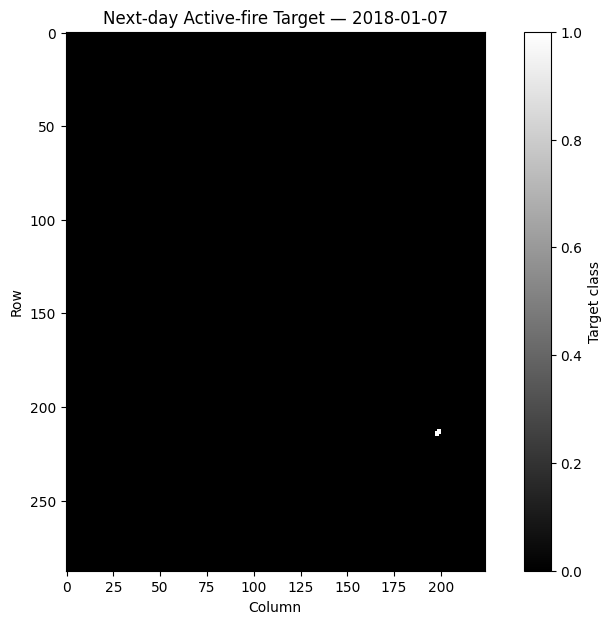

In [36]:
# 12. TARGET SPATIAL VISUALIZATION

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(target_np, cmap="gray", interpolation="nearest")
plt.title("Next-day Active-fire Target — 2018-01-07")
plt.xlabel("Column")
plt.ylabel("Row")
plt.colorbar(label="Target class")

plt.show()

In [37]:
# Count positive pixels by row and column

fire_rows, fire_cols = np.where(target_np == 1)

print("Fire pixel coordinates (row, column):")

for row, col in zip(fire_rows, fire_cols):
    print((int(row), int(col)))

Fire pixel coordinates (row, column):
(212, 198)
(212, 199)
(213, 197)
(213, 198)
(213, 199)
(214, 197)
(214, 198)
(214, 199)
(215, 197)
(215, 198)


## Spatial Distribution of Next-day Active-fire Target

Event: `fire_21458798`  
Target date: `2018-01-07`

The target visualization shows 10 positive pixels forming
one compact, contiguous cluster.

- Crop dimensions: 288 × 224
- Positive pixel count: 10
- Row coordinates: 212–215
- Column coordinates: 197–199
- Approximate location: lower-right region of the crop

The positive target occupies a very small portion of the
evaluation raster, illustrating the spatial sparsity and
class imbalance of this sample.

In [38]:
from pathlib import Path

PROJECT_ROOT = Path("/content/fireguard")

print("Project directory exists:", PROJECT_ROOT.exists())

print("\nNotebook files:")
for notebook in PROJECT_ROOT.rglob("*.ipynb"):
    print(notebook)


Project directory exists: True

Notebook files:
